# Neural PDE Exercises · 03
## Boundary constraints and smoothness

**Course section:** Network design and boundary constraints. **Time:** 35–50 minutes.
This notebook is self-contained: select **Restart Kernel and Run All Cells** in a
fresh Python 3.11+ kernel. CPU / float64; the supplied run is a working baseline.

[All practical exercises](README.md) · [Laboratory guide](../NOTEBOOK_README.md) ·
[Related laboratory](../Neural_PDE_01_foundations.ipynb)

**How to work:** predict the outcome, run the baseline, then edit the marked
settings and rerun all cells. Keep a small results table and answer the reflection
questions. Use the same seed and training budget when comparing methods.

**Notation:** $u$ is the reference state, $u_\theta$ the neural state,
$r_\theta=\mathcal L u_\theta-f$, $\widehat{\mathcal J}$ a sampled loss,
and $\mathcal E$ an energy. Reference values are used for checking errors after
training, except when observations are explicitly supplied.

## 1 · Predict before computing

For $-u''=\pi^2\sin(\pi x)$ on $(0,1)$ with $u(0)=u(1)=0$, compare the exact factor $u_\theta=x(1-x)N_\theta(x)$
with a soft boundary loss
$$\widehat{\mathcal J}_\lambda
=\frac1n\sum_j|r_\theta(x_j)/\pi^2|^2
+\frac\lambda2\left(|u_\theta(0)|^2+|u_\theta(1)|^2\right).$$
Every run starts with identical raw network weights and receives the same number
of Adam updates. A larger penalty changes both priorities and conditioning.

**Predict:** will the largest penalty produce the best interior solution?

In [1]:
import copy
import math
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 7
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                 ["teal", "orange", "pink", "blue", "navy"]]),
})

def network(width=20, activation=nn.Tanh):
    return nn.Sequential(nn.Linear(1, width), activation(),
                         nn.Linear(width, width), activation(), nn.Linear(width, 1))

class State(nn.Module):
    def __init__(self, initial, hard=True):
        super().__init__()
        self.net, self.hard = copy.deepcopy(initial), hard
    def forward(self, x):
        raw = self.net(x)
        return x*(1-x)*raw if self.hard else raw

def derivative(value, x):
    return torch.autograd.grad(value.sum(), x, create_graph=True)[0]

def forcing(x):
    return math.pi**2 * torch.sin(math.pi*x)

def residual(model, points):
    x = points.detach().clone().requires_grad_(True)
    u = model(x)
    return -derivative(derivative(u, x), x) - forcing(x)

def train(model, objective, steps=500, lr=0.004):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    started = time.perf_counter()
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = objective(model)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
    assert np.isfinite(history).all(), "The optimizer produced a non-finite objective."
    return np.asarray(history), time.perf_counter()-started

# This independent grid is never passed to a training objective.
check_x = torch.linspace(0, 1, 503).reshape(-1, 1)
check_u = torch.sin(math.pi*check_x).numpy().ravel()
boundary_x = torch.tensor([[0.0], [1.0]])

def diagnostics(model):
    with torch.no_grad():
        prediction = model(check_x).numpy().ravel()
        boundary_error = float(model(boundary_x).abs().max())
    scaled_residual = residual(model, check_x).detach().numpy().ravel()/math.pi**2
    relative_l2 = np.linalg.norm(prediction-check_u)/np.linalg.norm(check_u)
    return {"prediction": prediction, "relative_l2": float(relative_l2),
            "residual_rms": float(np.sqrt(np.mean(scaled_residual**2))),
            "boundary_max": boundary_error}

print(f"CPU / float64 / seed {SEED} / PyTorch {torch.__version__}")

CPU / float64 / seed 7 / PyTorch 2.10.0


Hard boundary      | boundary max 0.000e+00 | relative L2 8.018e-05 | residual RMS 2.821e-03


Soft λ=0.1         | boundary max 1.068e-04 | relative L2 1.076e-04 | residual RMS 2.504e-03


Soft λ=10          | boundary max 3.867e-03 | relative L2 5.724e-03 | residual RMS 6.860e-03


Soft λ=1000        | boundary max 9.885e-05 | relative L2 7.714e-01 | residual RMS 5.493e-01


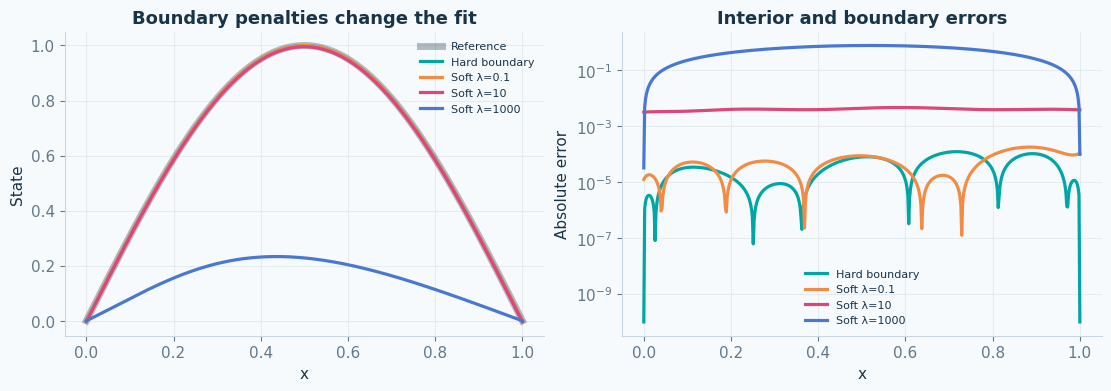

In [2]:
# EDIT HERE: compare weights, widths, and training budgets one at a time.
BOUNDARY_WEIGHTS = [0.1, 10.0, 1000.0]
WIDTH = 20
STEPS = 600
initial = network(width=WIDTH)
points = torch.linspace(0, 1, 50)[1:-1].reshape(-1, 1)
runs = [("Hard boundary", True, 0.0)] + [
    (f"Soft λ={weight:g}", False, weight) for weight in BOUNDARY_WEIGHTS]
reports = {}
for name, hard, weight in runs:
    model = State(initial, hard=hard)
    def objective(candidate, weight=weight):
        return ((residual(candidate, points)/math.pi**2).square().mean()
                + weight*candidate(boundary_x).square().mean())
    history, seconds = train(model, objective, STEPS)
    report = diagnostics(model)
    reports[name] = report
    print(f"{name:18s} | boundary max {report['boundary_max']:.3e} | "
          f"relative L2 {report['relative_l2']:.3e} | residual RMS {report['residual_rms']:.3e}")
assert reports["Hard boundary"]["boundary_max"] == 0.0
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].plot(check_x, check_u, color=palette["navy"], alpha=.3, lw=5, label="Reference")
for name, report in reports.items():
    axes[0].plot(check_x, report["prediction"], label=name)
    axes[1].semilogy(check_x, np.maximum(np.abs(report["prediction"]-check_u), 1e-10), label=name)
axes[0].set(title="Boundary penalties change the fit", xlabel="x", ylabel="State")
axes[1].set(title="Interior and boundary errors", xlabel="x", ylabel="Absolute error")
for ax in axes:
    ax.grid(); ax.legend(fontsize=8)
plt.show()

## 2 · Check what automatic differentiation differentiates

A raw ReLU network is piecewise affine in one dimension, so its second derivative
is zero away from kinks. The classical strong residual misses the distributional
contributions at the kinks. A hard factor can change this: $x(1-x)N_\theta$ is not
piecewise affine even when $N_\theta$ uses ReLU. It still has limited smoothness.

In [3]:
# Raw networks, without the hard boundary multiplier, isolate activation smoothness.
torch.manual_seed(SEED)
raw_relu = network(activation=nn.ReLU)
x_probe = torch.linspace(0.013, 0.987, 101).reshape(-1, 1).requires_grad_(True)
relu_d2 = derivative(derivative(raw_relu(x_probe), x_probe), x_probe)
torch.manual_seed(SEED)
raw_tanh = network(activation=nn.Tanh)
tanh_d2 = derivative(derivative(raw_tanh(x_probe), x_probe), x_probe)
print(f"Raw ReLU: max |AD second derivative| = {float(relu_d2.abs().max().detach()):.3e}")
print(f"Raw tanh: max |AD second derivative| = {float(tanh_d2.abs().max().detach()):.3e}")
assert torch.allclose(relu_d2, torch.zeros_like(relu_d2))

Raw ReLU: max |AD second derivative| = 0.000e+00
Raw tanh: max |AD second derivative| = 1.934e-01


## 3 · Your experiment and reflection

1. Record boundary error, state error, and independent residual RMS for at least
   four penalty weights. Repeat the experiment with twice the training budget.
2. Change `WIDTH` while keeping the budget fixed. Separate representational
   capacity from the optimizer's ability to use it.
3. Derive a hard ansatz for nonzero Dirichlet values $u(0)=a$, $u(1)=b$:
   begin with a lifting function $(1-x)a+xb$ and add a zero-boundary correction.
   Extend the code with $a=1$, $b=-1$ and update the reference solution accordingly.

**Hint:** adding an affine lifting does not change the forcing for $-u''$.
A hard constraint removes boundary mismatch but does not certify the interior PDE.

**Deliverable:** a penalty sweep table and a short explanation of why smoothness
requirements depend on whether the formulation uses first or second derivatives.